In [25]:
print("My Google Colab notebook is working!")

My Google Colab notebook is working!


In [26]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries are ready!")

All libraries are ready!


In [27]:



from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:

import os

print("Files in Colab:")
print(os.listdir("/content"))


In [ ]:

!pip install -q pandas numpy


In [ ]:

!python /content/generate_spotify_dataset.py \
    --out /content/spotify_data \
    --scale 0.05 \
    --seed 20261013


In [ ]:

import os

data_folder = "/content/spotify_data"

for root, dirs, files in os.walk(data_folder):
    for file in files:
        print(os.path.join(root, file))


In [ ]:

import pandas as pd
import os

file_path = "/content/spotify_data/dim_user.csv"

if os.path.exists(file_path):
    users = pd.read_csv(file_path)
    display(users.head())
    print("Rows and columns:", users.shape)
else:
    print("File not found. Check the file list from Step 6.")


In [ ]:

print("Column names:")
print(users.columns.tolist())

print("\nData types:")
print(users.dtypes)

print("\nDataset information:")
users.info()

print("\nMissing values:")
print(users.isnull().sum())


In [ ]:

import os
import pandas as pd

table_names = [
    "dim_artist",
    "dim_genre",
    "dim_country",
    "dim_date",
    "dim_album",
    "dim_track",
    "dim_playlist",
    "fact_subscription"
]

tables = {}

for name in table_names:
    path = f"/content/spotify_data/{name}.csv"

    if os.path.exists(path):
        tables[name] = pd.read_csv(path)
        print(name, tables[name].shape)
    else:
        print(name, "not found at the expected path")


In [ ]:

# Check duplicate rows
print("Duplicate user rows:", users.duplicated().sum())

# Check missing values
print("\nMissing values per column:")
print(users.isnull().sum())

# Check duplicate column names
print("\nDuplicate column names:",
      users.columns[users.columns.duplicated()].tolist())


In [ ]:

users_clean = users.copy()

# Remove completely duplicated rows
users_clean = users_clean.drop_duplicates()

# Remove rows without a user identifier, if this column exists
if "user_id" in users_clean.columns:
    users_clean = users_clean.dropna(subset=["user_id"])

print("Original shape:", users.shape)
print("Cleaned shape:", users_clean.shape)

display(users_clean.head())


In [ ]:

output_folder = "/content/spotify_silver"
os.makedirs(output_folder, exist_ok=True)

users_clean.to_csv(
    f"{output_folder}/dim_user_clean.csv",
    index=False
)

print("Cleaned users table saved.")


In [ ]:

print("Number of user records:", len(users_clean))
print("Number of columns:", len(users_clean.columns))

if "country_id" in users_clean.columns:
    print("\nUsers by country:")
    display(users_clean["country_id"].value_counts().head(10))


In [ ]:

events_folder = "/content/spotify_data/fact_playback_events"

if os.path.exists(events_folder):
    for root, dirs, files in os.walk(events_folder):
        for file in files:
            print(os.path.join(root, file))
else:
    print("Check the generated file list for the playback-events location.")


In [1]:

import os
import pandas as pd

events_folder = "/content/spotify_data/fact_playback_events"

csv_file = None

for root, dirs, files in os.walk(events_folder):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            break
    if csv_file:
        break

if csv_file:
    events = pd.read_csv(csv_file)
    print("File:", csv_file)
    print("Rows and columns:", events.shape)
    display(events.head(10))
else:
    print("No CSV file found. Check the file list from Step 14.")


File: /content/spotify_data/fact_playback_events/event_month=2025-06/part-0000.csv
Rows and columns: (8288, 18)


,event_id,user_id,track_id,event_ts,ingest_ts,ms_played,platform,context_type,context_id,reason_start,reason_end,skipped,shuffle,offline,country_code,connection_type,session_id,schema_version
0,149469,u_96f4aa59a922303e,81002PEddWwQsWK108mcxz,2025-05-31T15:43:47Z,2025-05-31 15:43:54,306529,mobile,playlist,tPReWCtG3Lp51I3WbKYIr9,trackdone,trackdone,False,False,False,KR,wifi,139414616,v3
1,149470,u_96f4aa59a922303e,IXB4D0mwZZUwcO5CPY64Lp,2025-05-31T21:02:48Z,2025-05-31 21:03:13,169757,mobile,collection,NaN,trackdone,endplay,False,True,False,KR,wifi,139414622,v3
2,149471,u_347c1435c48fc5b9,jxYAig6aq43Bo2JmZle2tL,2025-05-31T21:22:37Z,2025-05-31 21:23:14,17241,desktop,collection,NaN,trackdone,fwdbtn,True,True,False,AU,cellular,68414623,v3
3,149472,u_96f4aa59a922303e,ngTfJ7TsMDszMjvGd4xuIq,2025-05-31T21:31:08Z,2025-05-31 21:31:26,2272,mobile,collection,NaN,playbtn,fwdbtn,True,True,False,KR,wifi,139414622,v3
4,149473,u_7de4f2b9f88958e0,xpCUBvu7wGRIyXZtJWH0lo,2025-05-31T22:15:51Z,2025-05-31 22:15:52,275143,desktop,browse,NaN,clickrow,endplay,False,True,False,KR,wifi,136114623,v3
5,149474,u_1064a0c99ee429f5,XM9Lkx4o8NYXqho2rlMLBD,2025-05-31T22:46:25Z,2025-05-31 22:47:00,29900,mobile,collection,NaN,trackdone,fwdbtn,True,False,False,JP,cellular,124214623,v3
6,149475,u_96f4aa59a922303e,OhTq4ibcT5w219ucYwDbg1,2025-05-31T22:58:09Z,2025-05-31 22:58:51,174158,MOBILE,playlist,CJQ4G0gDZpnQWXw7FXfZwx,trackdone,trackdone,False,False,False,KR,cellular,139414623,v3
7,149476,u_9e24e2649a345b4d,AoELgE1Kg4vieEBY7BBOYc,2025-05-31T23:06:53Z,2025-05-31 23:07:34,148422,mobile,playlist,FQBWZlk0QhajHRPD6JFyRR,fwdbtn,trackdone,False,True,False,TR,cellular,53314618,v3
8,149478,u_08a6d0afc4d9965f,BlUazHO2aiBPDwMhvWQ4T7,2025-05-31T23:14:01Z,2025-05-31 23:14:15,148451,mobile,playlist,XxP65NL5DYGtJyHmFZ710j,backbtn,trackdone,False,False,False,AU,wifi,140214625,v3
9,149479,u_ba8df669098d8cea,mDTEZtwO9XMyD2b7noaImj,2025-05-31T23:24:29Z,2025-05-31 23:24:51,154782,mobile,playlist,qypoxouamVDH5XZJIH1WLx,trackdone,trackdone,False,False,False,KR,wifi,11614624,v3


In [2]:

display(events.head(20))


,event_id,user_id,track_id,event_ts,ingest_ts,ms_played,platform,context_type,context_id,reason_start,reason_end,skipped,shuffle,offline,country_code,connection_type,session_id,schema_version
0,149469,u_96f4aa59a922303e,81002PEddWwQsWK108mcxz,2025-05-31T15:43:47Z,2025-05-31 15:43:54,306529,mobile,playlist,tPReWCtG3Lp51I3WbKYIr9,trackdone,trackdone,False,False,False,KR,wifi,139414616,v3
1,149470,u_96f4aa59a922303e,IXB4D0mwZZUwcO5CPY64Lp,2025-05-31T21:02:48Z,2025-05-31 21:03:13,169757,mobile,collection,NaN,trackdone,endplay,False,True,False,KR,wifi,139414622,v3
2,149471,u_347c1435c48fc5b9,jxYAig6aq43Bo2JmZle2tL,2025-05-31T21:22:37Z,2025-05-31 21:23:14,17241,desktop,collection,NaN,trackdone,fwdbtn,True,True,False,AU,cellular,68414623,v3
3,149472,u_96f4aa59a922303e,ngTfJ7TsMDszMjvGd4xuIq,2025-05-31T21:31:08Z,2025-05-31 21:31:26,2272,mobile,collection,NaN,playbtn,fwdbtn,True,True,False,KR,wifi,139414622,v3
4,149473,u_7de4f2b9f88958e0,xpCUBvu7wGRIyXZtJWH0lo,2025-05-31T22:15:51Z,2025-05-31 22:15:52,275143,desktop,browse,NaN,clickrow,endplay,False,True,False,KR,wifi,136114623,v3
5,149474,u_1064a0c99ee429f5,XM9Lkx4o8NYXqho2rlMLBD,2025-05-31T22:46:25Z,2025-05-31 22:47:00,29900,mobile,collection,NaN,trackdone,fwdbtn,True,False,False,JP,cellular,124214623,v3
6,149475,u_96f4aa59a922303e,OhTq4ibcT5w219ucYwDbg1,2025-05-31T22:58:09Z,2025-05-31 22:58:51,174158,MOBILE,playlist,CJQ4G0gDZpnQWXw7FXfZwx,trackdone,trackdone,False,False,False,KR,cellular,139414623,v3
7,149476,u_9e24e2649a345b4d,AoELgE1Kg4vieEBY7BBOYc,2025-05-31T23:06:53Z,2025-05-31 23:07:34,148422,mobile,playlist,FQBWZlk0QhajHRPD6JFyRR,fwdbtn,trackdone,False,True,False,TR,cellular,53314618,v3
8,149478,u_08a6d0afc4d9965f,BlUazHO2aiBPDwMhvWQ4T7,2025-05-31T23:14:01Z,2025-05-31 23:14:15,148451,mobile,playlist,XxP65NL5DYGtJyHmFZ710j,backbtn,trackdone,False,False,False,AU,wifi,140214625,v3
9,149479,u_ba8df669098d8cea,mDTEZtwO9XMyD2b7noaImj,2025-05-31T23:24:29Z,2025-05-31 23:24:51,154782,mobile,playlist,qypoxouamVDH5XZJIH1WLx,trackdone,trackdone,False,False,False,KR,wifi,11614624,v3


In [3]:

print(events.columns.tolist())


['event_id', 'user_id', 'track_id', 'event_ts', 'ingest_ts', 'ms_played', 'platform', 'context_type', 'context_id', 'reason_start', 'reason_end', 'skipped', 'shuffle', 'offline', 'country_code', 'connection_type', 'session_id', 'schema_version']


In [4]:

display(events)



,event_id,user_id,track_id,event_ts,ingest_ts,ms_played,platform,context_type,context_id,reason_start,reason_end,skipped,shuffle,offline,country_code,connection_type,session_id,schema_version
0,149469,u_96f4aa59a922303e,81002PEddWwQsWK108mcxz,2025-05-31T15:43:47Z,2025-05-31 15:43:54,306529,mobile,playlist,tPReWCtG3Lp51I3WbKYIr9,trackdone,trackdone,False,False,False,KR,wifi,139414616,v3
1,149470,u_96f4aa59a922303e,IXB4D0mwZZUwcO5CPY64Lp,2025-05-31T21:02:48Z,2025-05-31 21:03:13,169757,mobile,collection,NaN,trackdone,endplay,False,True,False,KR,wifi,139414622,v3
2,149471,u_347c1435c48fc5b9,jxYAig6aq43Bo2JmZle2tL,2025-05-31T21:22:37Z,2025-05-31 21:23:14,17241,desktop,collection,NaN,trackdone,fwdbtn,True,True,False,AU,cellular,68414623,v3
3,149472,u_96f4aa59a922303e,ngTfJ7TsMDszMjvGd4xuIq,2025-05-31T21:31:08Z,2025-05-31 21:31:26,2272,mobile,collection,NaN,playbtn,fwdbtn,True,True,False,KR,wifi,139414622,v3
4,149473,u_7de4f2b9f88958e0,xpCUBvu7wGRIyXZtJWH0lo,2025-05-31T22:15:51Z,2025-05-31 22:15:52,275143,desktop,browse,NaN,clickrow,endplay,False,True,False,KR,wifi,136114623,v3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8283,151337,u_452463a8310023c3,zPBfeTxxSHfgThv7Rcem4V,2025-06-08T07:30:44Z,2025-08-01 01:30:01,242538,web,playlist,OOAnGEmxcRteN5kNYScec3,trackdone,trackdone,False,True,False,FR,wifi,61614792,v3
8284,150620,u_28e29836238bd0c8,OKjrvcY30rxJCnlcOS7Msz,2025-06-05T12:14:51Z,2025-08-01 07:54:53,28011,mobile,playlist,0R9cktudONN87dKojpSppf,fwdbtn,endplay,True,False,False,IN,wifi,121714729,v3
8285,150760,u_de3f8c7b103a13d8,Socjnekl52CudiZD5qICiL,2025-06-06T00:12:21Z,2025-08-01 10:54:14,41166,desktop,playlist,dmydobV3EcikPbdUTzM8jI,appload,endplay,False,False,False,BR,wifi,105214733,v3
8286,154065,u_67ad106d6b9eec8b,mg7kZJe70FmN1pbJndQyXG,2025-06-18T15:10:21Z,2025-08-07 00:07:53,130956,mobile,playlist,OCtzrziOHyHetIc0Eqc2kd,trackdone,endplay,False,True,False,DE,NaN,2515040,v3


In [5]:

events.info()

print("\nMissing values:")
print(events.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8288 entries, 0 to 8287
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_id         8288 non-null   int64 
 1   user_id          8288 non-null   object
 2   track_id         8277 non-null   object
 3   event_ts         8288 non-null   object
 4   ingest_ts        8288 non-null   object
 5   ms_played        8288 non-null   int64 
 6   platform         8288 non-null   object
 7   context_type     8161 non-null   object
 8   context_id       4479 non-null   object
 9   reason_start     8288 non-null   object
 10  reason_end       8230 non-null   object
 11  skipped          8288 non-null   bool  
 12  shuffle          8288 non-null   bool  
 13  offline          8288 non-null   bool  
 14  country_code     8129 non-null   object
 15  connection_type  8023 non-null   object
 16  session_id       8288 non-null   int64 
 17  schema_version   8288 non-null   

In [6]:

import pandas as pd
import numpy as np
import os

print("Dataset shape:", events.shape)
print("\nColumn names:")
print(events.columns.tolist())

print("\nFirst 10 rows:")
display(events.head(10))

print("\nData types and non-null counts:")
events.info()


Dataset shape: (8288, 18)

Column names:
['event_id', 'user_id', 'track_id', 'event_ts', 'ingest_ts', 'ms_played', 'platform', 'context_type', 'context_id', 'reason_start', 'reason_end', 'skipped', 'shuffle', 'offline', 'country_code', 'connection_type', 'session_id', 'schema_version']

First 10 rows:


,event_id,user_id,track_id,event_ts,ingest_ts,ms_played,platform,context_type,context_id,reason_start,reason_end,skipped,shuffle,offline,country_code,connection_type,session_id,schema_version
0,149469,u_96f4aa59a922303e,81002PEddWwQsWK108mcxz,2025-05-31T15:43:47Z,2025-05-31 15:43:54,306529,mobile,playlist,tPReWCtG3Lp51I3WbKYIr9,trackdone,trackdone,False,False,False,KR,wifi,139414616,v3
1,149470,u_96f4aa59a922303e,IXB4D0mwZZUwcO5CPY64Lp,2025-05-31T21:02:48Z,2025-05-31 21:03:13,169757,mobile,collection,NaN,trackdone,endplay,False,True,False,KR,wifi,139414622,v3
2,149471,u_347c1435c48fc5b9,jxYAig6aq43Bo2JmZle2tL,2025-05-31T21:22:37Z,2025-05-31 21:23:14,17241,desktop,collection,NaN,trackdone,fwdbtn,True,True,False,AU,cellular,68414623,v3
3,149472,u_96f4aa59a922303e,ngTfJ7TsMDszMjvGd4xuIq,2025-05-31T21:31:08Z,2025-05-31 21:31:26,2272,mobile,collection,NaN,playbtn,fwdbtn,True,True,False,KR,wifi,139414622,v3
4,149473,u_7de4f2b9f88958e0,xpCUBvu7wGRIyXZtJWH0lo,2025-05-31T22:15:51Z,2025-05-31 22:15:52,275143,desktop,browse,NaN,clickrow,endplay,False,True,False,KR,wifi,136114623,v3
5,149474,u_1064a0c99ee429f5,XM9Lkx4o8NYXqho2rlMLBD,2025-05-31T22:46:25Z,2025-05-31 22:47:00,29900,mobile,collection,NaN,trackdone,fwdbtn,True,False,False,JP,cellular,124214623,v3
6,149475,u_96f4aa59a922303e,OhTq4ibcT5w219ucYwDbg1,2025-05-31T22:58:09Z,2025-05-31 22:58:51,174158,MOBILE,playlist,CJQ4G0gDZpnQWXw7FXfZwx,trackdone,trackdone,False,False,False,KR,cellular,139414623,v3
7,149476,u_9e24e2649a345b4d,AoELgE1Kg4vieEBY7BBOYc,2025-05-31T23:06:53Z,2025-05-31 23:07:34,148422,mobile,playlist,FQBWZlk0QhajHRPD6JFyRR,fwdbtn,trackdone,False,True,False,TR,cellular,53314618,v3
8,149478,u_08a6d0afc4d9965f,BlUazHO2aiBPDwMhvWQ4T7,2025-05-31T23:14:01Z,2025-05-31 23:14:15,148451,mobile,playlist,XxP65NL5DYGtJyHmFZ710j,backbtn,trackdone,False,False,False,AU,wifi,140214625,v3
9,149479,u_ba8df669098d8cea,mDTEZtwO9XMyD2b7noaImj,2025-05-31T23:24:29Z,2025-05-31 23:24:51,154782,mobile,playlist,qypoxouamVDH5XZJIH1WLx,trackdone,trackdone,False,False,False,KR,wifi,11614624,v3



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8288 entries, 0 to 8287
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_id         8288 non-null   int64 
 1   user_id          8288 non-null   object
 2   track_id         8277 non-null   object
 3   event_ts         8288 non-null   object
 4   ingest_ts        8288 non-null   object
 5   ms_played        8288 non-null   int64 
 6   platform         8288 non-null   object
 7   context_type     8161 non-null   object
 8   context_id       4479 non-null   object
 9   reason_start     8288 non-null   object
 10  reason_end       8230 non-null   object
 11  skipped          8288 non-null   bool  
 12  shuffle          8288 non-null   bool  
 13  offline          8288 non-null   bool  
 14  country_code     8129 non-null   object
 15  connection_type  8023 non-null   object
 16  session_id       8288 non-null   int64 
 17  

In [7]:

print("Missing values per column:")
display(events.isnull().sum().to_frame("missing_count"))

print("Duplicate rows:", events.duplicated().sum())

print("\nSummary statistics:")
display(events.describe(include="all").T)


Missing values per column:


,missing_count
event_id,0
user_id,0
track_id,11
event_ts,0
ingest_ts,0
ms_played,0
platform,0
context_type,127
context_id,3809
reason_start,0


Duplicate rows: 36

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,8288.0,NaN,NaN,NaN,153581.904319,2374.544756,149469.0,151523.75,153582.5,155635.25,157694.0
user_id,8288,823,u_96f4aa59a922303e,315,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_id,8277,2454,91L0TVGinDZkJRiktGAMLZ,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_ts,8288,8206,2025-06-08T06:58:57Z,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ingest_ts,8288,8234,2025-06-05 15:46:07,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ms_played,8288.0,NaN,NaN,NaN,154063.59013,105295.110696,-1.0,41325.75,165526.0,226328.0,573363.0
platform,8288,14,mobile,5098,NaN,NaN,NaN,NaN,NaN,NaN,NaN
context_type,8161,7,playlist,2616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
context_id,4479,1267,7Gyhu3WxztfP7efdPl8kBb,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reason_start,8288,7,trackdone,4545,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

events_clean = events.copy()

# Remove exact duplicate rows
events_clean = events_clean.drop_duplicates()

print("Original rows:", len(events))
print("Rows after deduplication:", len(events_clean))


Original rows: 8288
Rows after deduplication: 8252


In [9]:

events_clean = events.copy()

# Remove exact duplicate rows
events_clean = events_clean.drop_duplicates()

print("Original rows:", len(events))
print("Rows after deduplication:", len(events_clean))



Original rows: 8288
Rows after deduplication: 8252


In [10]:

silver_folder = "/content/spotify_silver"
os.makedirs(silver_folder, exist_ok=True)

silver_file = os.path.join(
    silver_folder,
    "playback_events_clean.csv"
)

events_clean.to_csv(silver_file, index=False)

print("Saved to:", silver_file)



Saved to: /content/spotify_silver/playback_events_clean.csv


In [11]:

silver_folder = "/content/spotify_silver"
os.makedirs(silver_folder, exist_ok=True)

silver_file = os.path.join(
    silver_folder,
    "playback_events_clean.csv"
)

events_clean.to_csv(silver_file, index=False)

print("Saved to:", silver_file)


Saved to: /content/spotify_silver/playback_events_clean.csv


In [12]:

data_folder = "/content/spotify_data"

table_names = [
    "dim_user",
    "dim_artist",
    "dim_genre",
    "dim_country",
    "dim_date",
    "dim_album",
    "dim_track",
    "dim_playlist",
    "fact_subscription"
]

tables = {}

for name in table_names:
    path = os.path.join(data_folder, name + ".csv")

    if os.path.exists(path):
        tables[name] = pd.read_csv(path)
        print(f"{name}: {tables[name].shape}")
    else:
        print(f"{name}: CSV not found at expected path")


dim_user: (1499, 10)
dim_artist: (303, 9)
dim_genre: (19, 2)
dim_country: (22, 5)
dim_date: (1096, 13)
dim_album: (1226, 8)
dim_track: (8902, 22)
dim_playlist: (790, 9)
fact_subscription: (2670, 10)


In [13]:

silver_tables = {}

for name, df in tables.items():
    cleaned = df.copy()
    cleaned = cleaned.drop_duplicates()

    silver_tables[name] = cleaned

    print(
        name,
        "| original rows:", len(df),
        "| cleaned rows:", len(cleaned)
    )


dim_user | original rows: 1499 | cleaned rows: 1499
dim_artist | original rows: 303 | cleaned rows: 303
dim_genre | original rows: 19 | cleaned rows: 19
dim_country | original rows: 22 | cleaned rows: 22
dim_date | original rows: 1096 | cleaned rows: 1096
dim_album | original rows: 1226 | cleaned rows: 1226
dim_track | original rows: 8902 | cleaned rows: 8902
dim_playlist | original rows: 790 | cleaned rows: 790
fact_subscription | original rows: 2670 | cleaned rows: 2670


In [14]:

for name, df in tables.items():
    print(f"\n{name}")
    print(df.columns.tolist())



dim_user
['user_id', 'signup_date', 'country_code', 'age_band', 'gender', 'primary_platform', 'acquisition_channel', 'account_status', 'closed_date', 'updated_at']

dim_artist
['artist_id', 'artist_name', 'artist_type', 'country_code', 'primary_genre_id', 'followers', 'popularity', 'is_verified', 'debut_year']

dim_genre
['genre_id', 'genre_name']

dim_country
['country_code', 'utc_offset_minutes', 'price_index_vs_us', 'billing_currency', 'listener_share']

dim_date
['date_key', 'date', 'year', 'quarter', 'month', 'day', 'day_of_week', 'day_name', 'is_weekend', 'week_of_year', 'is_release_friday', 'holiday_name', 'is_holiday']

dim_album
['album_id', 'artist_id', 'album_name', 'album_type', 'release_date', 'release_date_precision', 'total_tracks', 'label']

dim_track
['track_id', 'album_id', 'artist_id', 'track_name', 'track_number', 'duration_ms', 'explicit', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'livenes

In [15]:

print(events_clean.columns.tolist())


['event_id', 'user_id', 'track_id', 'event_ts', 'ingest_ts', 'ms_played', 'platform', 'context_type', 'context_id', 'reason_start', 'reason_end', 'skipped', 'shuffle', 'offline', 'country_code', 'connection_type', 'session_id', 'schema_version']


In [17]:

for name, df in tables.items():
    print(f"\n{name}")
    print(df.columns.tolist())



dim_user
['user_id', 'signup_date', 'country_code', 'age_band', 'gender', 'primary_platform', 'acquisition_channel', 'account_status', 'closed_date', 'updated_at']

dim_artist
['artist_id', 'artist_name', 'artist_type', 'country_code', 'primary_genre_id', 'followers', 'popularity', 'is_verified', 'debut_year']

dim_genre
['genre_id', 'genre_name']

dim_country
['country_code', 'utc_offset_minutes', 'price_index_vs_us', 'billing_currency', 'listener_share']

dim_date
['date_key', 'date', 'year', 'quarter', 'month', 'day', 'day_of_week', 'day_name', 'is_weekend', 'week_of_year', 'is_release_friday', 'holiday_name', 'is_holiday']

dim_album
['album_id', 'artist_id', 'album_name', 'album_type', 'release_date', 'release_date_precision', 'total_tracks', 'label']

dim_track
['track_id', 'album_id', 'artist_id', 'track_name', 'track_number', 'duration_ms', 'explicit', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'livenes

In [18]:

if (
    "track_id" in events_clean.columns
    and "dim_track" in silver_tables
    and "track_id" in silver_tables["dim_track"].columns
):
    known_tracks = set(
        silver_tables["dim_track"]["track_id"].dropna()
    )

    unknown_track_rows = ~events_clean["track_id"].isin(known_tracks)

    print("Events with unknown track IDs:", unknown_track_rows.sum())
else:
    print("Check track_id column names before running this relationship test.")



Events with unknown track IDs: 13


In [19]:

gold_track_activity = (
    events_clean
    .groupby("track_id")
    .size()
    .reset_index(name="playback_event_count")
    .sort_values("playback_event_count", ascending=False)
)

display(gold_track_activity.head(10))


,track_id,playback_event_count
343,91L0TVGinDZkJRiktGAMLZ,119
1446,aUovp57wKIncMTVminqNZb,102
553,ECXDy6duCtMnL7CDUdN8Sa,94
1961,n7hy5Eepu05cQcdgSu57H2,82
2231,uBOkzDHdodhhRpC8RL2Fct,79
455,BlUazHO2aiBPDwMhvWQ4T7,67
1309,XMZMkfloc2WR5wS3KDUs4J,56
501,D9XohVEVjjXaOyVlSgN4pF,55
1404,ZVRVbz0iP3fwjmyCthakAi,45
2185,svdjn2Xj6OSo9YHGFOL5S8,43


In [20]:

import os
import pandas as pd

events_folder = "/content/spotify_data/fact_playback_events"
event_files = []

for root, dirs, files in os.walk(events_folder):
    for file in files:
        if file.lower().endswith(".csv"):
            event_files.append(os.path.join(root, file))

event_files.sort()

print("CSV files found:", len(event_files))


CSV files found: 36


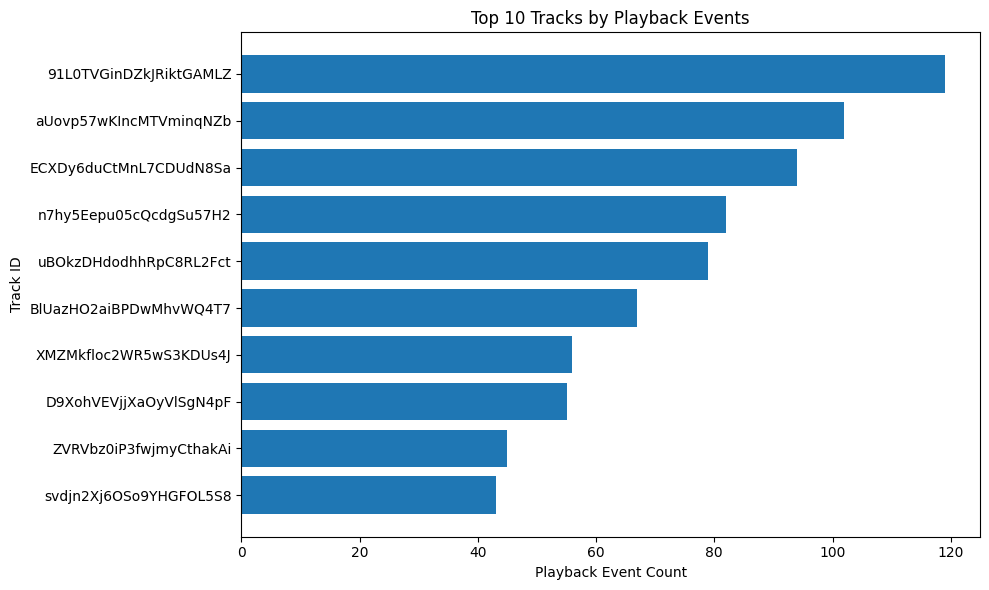

In [21]:

import matplotlib.pyplot as plt

top_tracks = gold_track_activity.head(10).sort_values(
    "playback_event_count"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_tracks["track_id"].astype(str),
    top_tracks["playback_event_count"]
)
plt.title("Top 10 Tracks by Playback Events")
plt.xlabel("Playback Event Count")
plt.ylabel("Track ID")
plt.tight_layout()
plt.show()


In [22]:

import os
import pandas as pd

events_folder = "/content/spotify_data/fact_playback_events"
event_files = []

for root, dirs, files in os.walk(events_folder):
    for file in files:
        if file.lower().endswith(".csv"):
            event_files.append(os.path.join(root, file))

event_files.sort()

print("CSV files found:", len(event_files))


CSV files found: 36


In [23]:

track_counts = {}

for path in event_files:
    for chunk in pd.read_csv(path, chunksize=100_000):
        if "track_id" not in chunk.columns:
            raise ValueError(f"track_id missing in {path}")

        counts = chunk["track_id"].value_counts()

        for track_id, count in counts.items():
            track_counts[track_id] = (
                track_counts.get(track_id, 0) + int(count)
            )

gold_all_tracks = pd.DataFrame(
    track_counts.items(),
    columns=["track_id", "playback_event_count"]
).sort_values("playback_event_count", ascending=False)

display(gold_all_tracks.head(10))


,track_id,playback_event_count
0,91L0TVGinDZkJRiktGAMLZ,3596
1,aUovp57wKIncMTVminqNZb,3120
4,ECXDy6duCtMnL7CDUdN8Sa,2943
2,BlUazHO2aiBPDwMhvWQ4T7,2744
3,n7hy5Eepu05cQcdgSu57H2,2534
5,uBOkzDHdodhhRpC8RL2Fct,2381
6,D9XohVEVjjXaOyVlSgN4pF,2272
3880,qSTaP2oFIWmWDamppx1tD1,2108
6930,K6CqD18wWzgXz5YjGfgLI8,1949
6929,vkftF1QZouIYOrlE4BacTu,1767


In [24]:

gold_folder = "/content/spotify_gold"
os.makedirs(gold_folder, exist_ok=True)

gold_all_tracks.to_csv(
    f"{gold_folder}/track_playback_summary.csv",
    index=False
)

print("Gold analytics table saved.")


Gold analytics table saved.


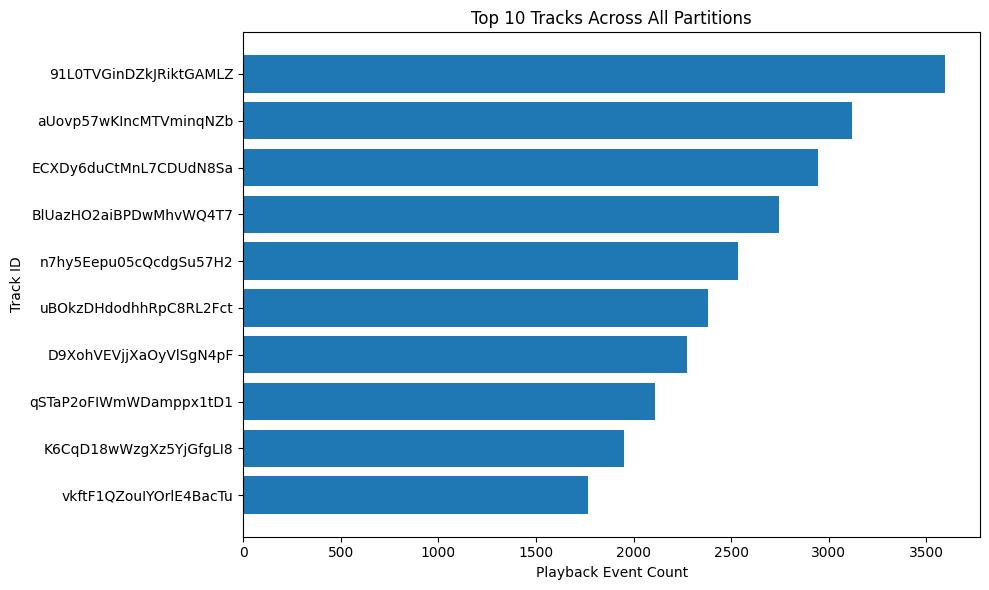

In [25]:

top_tracks = gold_all_tracks.head(10).sort_values(
    "playback_event_count"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_tracks["track_id"].astype(str),
    top_tracks["playback_event_count"]
)
plt.title("Top 10 Tracks Across All Partitions")
plt.xlabel("Playback Event Count")
plt.ylabel("Track ID")
plt.tight_layout()
plt.show()


In [26]:

project_output = "/content/spotify_project_output"
os.makedirs(project_output, exist_ok=True)

gold_all_tracks.to_csv(
    f"{project_output}/track_playback_summary.csv",
    index=False
)

for name, df in silver_tables.items():
    df.to_csv(
        f"{project_output}/{name}_clean.csv",
        index=False
    )

print("Files saved:")
print(os.listdir(project_output))


Files saved:
['dim_playlist_clean.csv', 'dim_country_clean.csv', 'dim_album_clean.csv', 'dim_artist_clean.csv', 'dim_track_clean.csv', 'fact_subscription_clean.csv', 'dim_date_clean.csv', 'track_playback_summary.csv', 'dim_genre_clean.csv', 'dim_user_clean.csv']


In [27]:

import shutil

zip_path = shutil.make_archive(
    "/content/spotify_project_output",
    "zip",
    project_output
)

print("ZIP created:", zip_path)


ZIP created: /content/spotify_project_output.zip


In [28]:

from google.colab import files

files.download("/content/spotify_project_output.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>